# Hydro Lens — Phase 2: Multi-Class Retrain (R2 + R4 + R5)

**Model:** YOLOv8n · **Task:** 5-class detection (fragment, fiber, film, foam, pellet) · **Epochs:** 50 · **Device:** CUDA (RTX 4060)

| Item | Value |
|------|-------|
| Dataset | `data/processed_multi/` — R2 all-plastic + R4 microplastic-final (OBB→HBB) + R5 annotations (11→5 classes) |
| Groups | 7,662 original-image groups (Roboflow `.rf.` derivatives kept in one split — leakage prevented) |
| Splits | 11,585 train / 1,364 val / 682 test (group-aware 85/10/5) |
| Classes | 5: 0 fragment, 1 fiber, 2 film, 3 foam, 4 pellet (dirt dropped) |
| Image size | 640 · Batch 16 · Seed 42 · patience 20 |
| Start weights | `models/best.pt` (binary v1 — detection head rebuilt for nc=5) |
| Artifacts | `training/multiclass_phase2_v1/` (weights, results.csv, training_curves.png, comparison.json) |

**Run order:** GPU check → Dataset check → Train → Test evaluation → Metrics + accuracy graphs.
Run headless with: `python training/run_notebook.py train_multiclass_phase2.ipynb`

**Note:** no automatic promotion to `models/best.pt` — the deployed binary model and the
multi-class model are not 1:1 comparable; deployment is a separate decision.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd
import torch
from ultralytics import YOLO

ROOT = Path.cwd()
if not (ROOT / "data").exists():
    ROOT = ROOT.parent

OUT_DIR = ROOT / "training" / "multiclass_phase2_v1"
OUT_DIR.mkdir(parents=True, exist_ok=True)

DATA_YAML = ROOT / "data" / "processed_multi" / "data.yaml"
WEIGHTS = OUT_DIR / "train" / "weights" / "best.pt"
DEPLOYED = ROOT / "models" / "best.pt"

EPOCHS, BATCH, IMGSZ, SEED, PATIENCE = 50, 16, 640, 42, 20

print(f"repo:      {ROOT}")
print(f"artifacts: {OUT_DIR}")
print(f"epochs={EPOCHS} batch={BATCH} imgsz={IMGSZ} seed={SEED} patience={PATIENCE}")

repo:      C:\Users\neera\Hydro-Lens
artifacts: C:\Users\neera\Hydro-Lens\training\multiclass_phase2_v1
epochs=50 batch=16 imgsz=640 seed=42 patience=20


## 0 · GPU check (hard requirement)

GPU-only run — raises instead of silently falling back to CPU.

In [2]:
if not torch.cuda.is_available():
    raise RuntimeError("CUDA not available — Phase 2 training must run on the RTX 4060.")

DEVICE = "cuda"
gpu = torch.cuda.get_device_name(0)
vram_gb = torch.cuda.get_device_properties(0).total_mem / 1e9 if hasattr(torch.cuda.get_device_properties(0), "total_mem") else torch.cuda.get_device_properties(0).total_memory / 1e9
print(f"GPU: {gpu} ({vram_gb:.1f} GB)  |  torch {torch.__version__}")

GPU: NVIDIA GeForce RTX 4060 Laptop GPU (8.6 GB)  |  torch 2.14.1+cu126


## 1 · Dataset check

`data/processed_multi/` is built by `training/prepare_multi_dataset.py` (already run).
Verifies class count and split integrity before training.

In [3]:
import yaml

assert DATA_YAML.exists(), f"{DATA_YAML} missing — run: python training/prepare_multi_dataset.py"
meta = yaml.safe_load(DATA_YAML.read_text())
assert meta["nc"] == 5, meta

manifest = json.loads((ROOT / "data" / "processed_multi" / "manifest.json").read_text())
groups_per_split = {}
for m in manifest["images"]:
    groups_per_split.setdefault(m["split"], set()).add(m["group_id"])
overlap = set.intersection(*groups_per_split.values()) if len(groups_per_split) > 1 else set()
assert not overlap, f"LEAKAGE: {len(overlap)} groups appear in multiple splits"

print("classes:", meta["names"])
print("leakage check: PASS — no original-image group spans multiple splits")
print("boxes kept:", manifest["boxes_kept"], "| dropped (dirt):", manifest["boxes_dropped"])

classes: {0: 'fragment', 1: 'fiber', 2: 'film', 3: 'foam', 4: 'pellet'}
leakage check: PASS — no original-image group spans multiple splits
boxes kept: 35852 | dropped (dirt): 1944


## 2 · Train (50 epochs)

Fine-tunes from the deployed binary model; Ultralytics rebuilds the detection head for nc=5.

In [4]:
if WEIGHTS.exists():
    print(f"already trained, skipping — {WEIGHTS} (delete train/ to retrain)")
else:
    model = YOLO(str(DEPLOYED))
    results = model.train(
        data=str(DATA_YAML),
        epochs=EPOCHS,
        batch=BATCH,
        imgsz=IMGSZ,
        seed=SEED,
        patience=PATIENCE,
        device=DEVICE,
        workers=0,  # spawn DataLoader workers hang in Jupyter on Windows
        project=str(OUT_DIR),
        name="train",
        exist_ok=True,
        verbose=True,
    )
    print("training done:", results.save_dir)

already trained, skipping — C:\Users\neera\Hydro-Lens\training\multiclass_phase2_v1\train\weights\best.pt (delete train/ to retrain)


## 3 · Held-out test evaluation

Evaluates the best checkpoint on the held-out group-aware **test** split (682 images).

In [5]:
best = YOLO(str(WEIGHTS))
metrics = best.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, device=DEVICE, workers=0, verbose=True)

per_class = {}
names = metrics.names
p, r, ap50, ap = metrics.box.p, metrics.box.r, metrics.box.ap50, metrics.box.ap
for pos, class_id in enumerate(metrics.box.ap_class_index):
    n = names[class_id]
    per_class[n] = {
        "precision": round(float(p[pos]), 4),
        "recall": round(float(r[pos]), 4),
        "mAP50": round(float(ap50[pos]), 4),
        "mAP50-95": round(float(ap[pos]), 4),
    }

new_metrics = {
    "precision": round(float(metrics.box.mp), 4),
    "recall": round(float(metrics.box.mr), 4),
    "mAP50": round(float(metrics.box.map50), 4),
    "mAP50-95": round(float(metrics.box.map), 4),
}

n_params = sum(p.numel() for p in best.model.parameters())
model_size_mb = WEIGHTS.stat().st_size / 1e6

comparison = {
    "run": "multiclass_phase2_v1",
    "task": "5-class detection (fragment/fiber/film/foam/pellet)",
    "dataset": "processed_multi: R2+R4+R5, group-aware 85/10/5",
    "test_images": int(len(list((DATA_YAML.parent / "test" / "images").glob("*")))),
    "overall": new_metrics,
    "per_class": per_class,
    "parameters": n_params,
    "model_size_mb": round(model_size_mb, 2),
    "epochs_trained": EPOCHS,
    "start_weights": str(DEPLOYED.relative_to(ROOT)),
}
(OUT_DIR / "comparison.json").write_text(json.dumps(comparison, indent=2))
print(json.dumps(comparison, indent=2))

Ultralytics 8.4.174  Python-3.13.15 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)


Model summary (fused): 72 layers, 3,006,623 parameters, 0 gradients, 8.1 GFLOPs


WARNING val: Slow image access detected (ping: 0.20.0 ms, read: 32.215.2 MB/s, size: 20.4 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips


val: Scanning C:\Users\neera\Hydro-Lens\data\processed_multi\test\labels.cache... 682 images, 54 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 682/682 220.0Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 2% ──────────── 1/43 1.1it/s 0.3s<39.7s

...

                  film         50        122      0.788      0.762      0.816       0.37


                pellet         50        150      0.801       0.86      0.808      0.362


Speed: 0.1ms preprocess, 1.1ms inference, 0.0ms loss, 1.3ms postprocess per image


Results saved to C:\Users\neera\Hydro-Lens\runs\detect\val-4


{
  "run": "multiclass_phase2_v1",
  "task": "5-class detection (fragment/fiber/film/foam/pellet)",
  "dataset": "processed_multi: R2+R4+R5, group-aware 85/10/5",
  "test_images": 682,
  "overall": {
    "precision": 0.8188,
    "recall": 0.806,
    "mAP50": 0.8367,
    "mAP50-95": 0.4822
  },
  "per_class": {
    "fragment": {
      "precision": 0.866,
      "recall": 0.874,
      "mAP50": 0.9052,
      "mAP50-95": 0.6082
    },
    "fiber": {
      "precision": 0.8197,
      "recall": 0.7278,
      "mAP50": 0.8173,
      "mAP50-95": 0.5892
    },
    "film": {
      "precision": 0.788,
      "recall": 0.7623,
      "mAP50": 0.8164,
      "mAP50-95": 0.3699
    },
    "pellet": {
      "precision": 0.8013,
      "recall": 0.86,
      "mAP50": 0.8078,
      "mAP50-95": 0.3617
    }
  },
  "parameters": 3011823,
  "model_size_mb": 6.25,
  "epochs_trained": 50,
  "start_weights": "models\\best.pt"
}


## 4 · Accuracy graphs

Training curves (losses + mAP/precision/recall per epoch) saved as `training_curves.png`.
Ultralytics also saves PR/F1/confusion curves under the run folder.

saved: C:\Users\neera\Hydro-Lens\training\multiclass_phase2_v1\training_curves.png


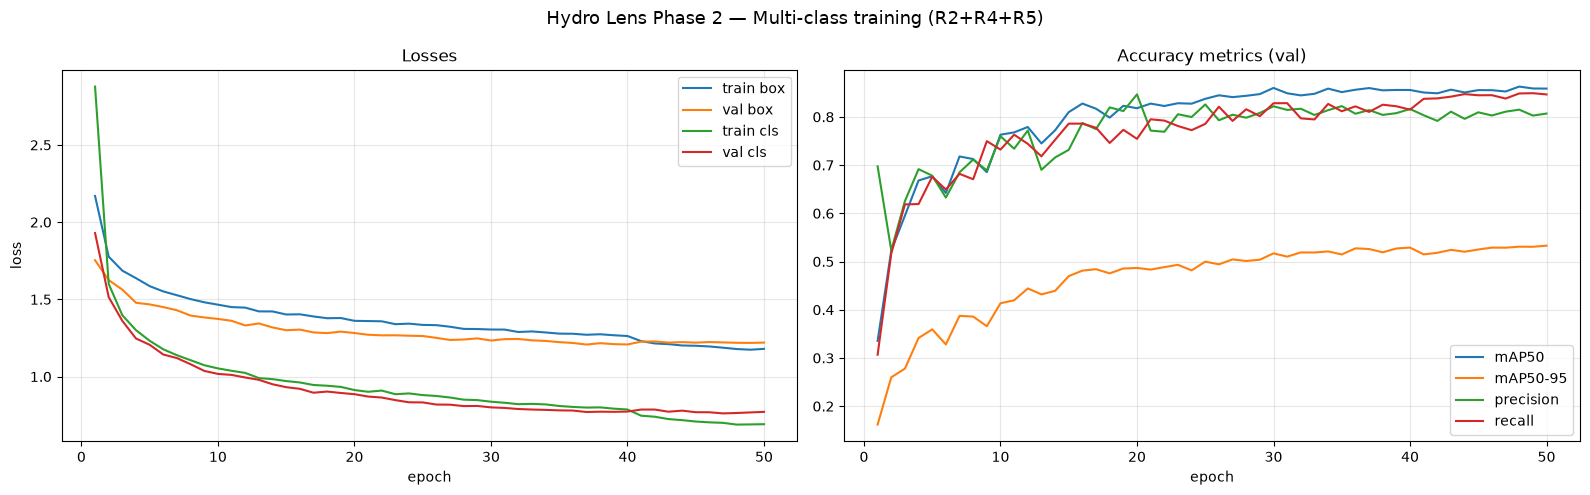

In [6]:
%matplotlib inline
df = pd.read_csv(OUT_DIR / "train" / "results.csv")
df.columns = [c.strip() for c in df.columns]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(df["epoch"], df["train/box_loss"], label="train box")
axes[0].plot(df["epoch"], df["val/box_loss"], label="val box")
axes[0].plot(df["epoch"], df["train/cls_loss"], label="train cls")
axes[0].plot(df["epoch"], df["val/cls_loss"], label="val cls")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("loss")
axes[0].set_title("Losses"); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP50")
axes[1].plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP50-95")
axes[1].plot(df["epoch"], df["metrics/precision(B)"], label="precision")
axes[1].plot(df["epoch"], df["metrics/recall(B)"], label="recall")
axes[1].set_xlabel("epoch")
axes[1].set_title("Accuracy metrics (val)")
axes[1].legend(); axes[1].grid(alpha=0.3)

fig.suptitle("Hydro Lens Phase 2 — Multi-class training (R2+R4+R5)", fontsize=13)
fig.tight_layout()
curves = OUT_DIR / "training_curves.png"
fig.savefig(curves, dpi=150)
print("saved:", curves)